# HW1 – Introduction and Learnability

## 1. Data Generation

We consider the input space $X = [0,1]$.
The target function is a threshold classifier defined by:
$$
f_\theta(x) =
\begin{cases}
1 & \text{if } x > \theta \\
0 & \text{otherwise}
\end{cases}
$$
In the realizable setting, the labels are generated according to:
$$
y = f_\theta(x)
$$
We will generate training datasets with different sample sizes:
$m \in \{5, 10, 20, 50, 100, 200\}$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#Define the true parameter and sample sizes
theta = 0.6
sample_sizes = [5, 10, 20, 50, 100, 200]

In [4]:
#Generate a dataset with a given sample size and true parameter
def generate_dataset(m, theta):
    X = np.random.uniform(0, 1, m) 
    Y = np.where(X > theta, 1, 0) 
    return X, Y

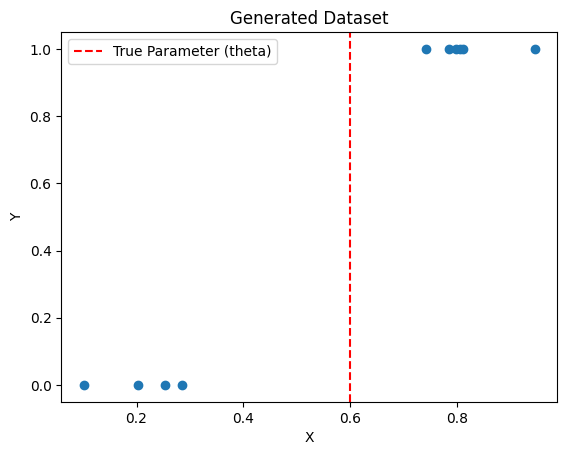

In [10]:
#Visualize one dataset
X, Y = generate_dataset(10, theta)
plt.scatter(X, Y)
plt.axvline(x=theta, color='r', linestyle='--', label='True Parameter (theta)')
plt.title('Generated Dataset')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()

## 2.  Implementation of ERM

Implement an ERM algorithm over the hypothesis class of threshold classifiers.

In [11]:
#Define the ERM algorithm 
#The strategy I chose : 
    #look at the results of the dataset
    #look for the maximum value of X that has a Y=0 
    #look for the minimum value of X that has a Y=1
    #take the average of these two values as the estimate for theta

def ERM(X, Y):
    if np.any(Y == 0): #if there are Y=0 in the dataset
        max_X_Y0 = np.max(X[Y == 0]) #we take the maximum value of X having Y=0
    else:
        max_X_Y0 = 0 #if there is no Y=0 we take 0

    if np.any(Y == 1): #if there are Y=1 in the dataset
        min_X_Y1 = np.min(X[Y == 1]) #we take the minimum value of X having Y=1
    else:
        min_X_Y1 = 1 #if there is no Y=1 we take 1

    theta_hat = (max_X_Y0 + min_X_Y1) / 2 # threshold halfway between the two groups
    return theta_hat

In [ ]:
#Test the ERM algorithm on one training dataset
theta_hat = ERM(X, Y)
Y_pred = np.where(X > theta_hat, 1, 0)

empirical_error = np.mean(Y_pred != Y)
print("Empirical error:", empirical_error) #hypothesis selected by the ERM has an empirical error of 0 on the training dataset

True theta: 0.6
Estimated theta: 0.5141245661644944
Empirical error: 0.0


In [ ]:
#Generate a large test dataset to evaluate the performance of the ERM algorithm
X_test, Y_test = generate_dataset(10000, theta)
Y_test_pred = np.where(X_test > theta_hat, 1, 0) # Predictions made by the hypothesis selected by the ERM algorithm

true_error = np.mean(Y_test_pred != Y_test)
print("True error:", true_error)

True error: 0.0833


## 3. Performance for Different Training Sample Sizes

We now evaluate the ERM algorithm for different training sample sizes:
$m \in \{5, 10, 20, 50, 100, 200\}$.

For each sample size, we generate a training dataset, learn a threshold using ERM, and evaluate both the empirical error and the true error.

In [ ]:
for m in sample_sizes:
    # Generate a new training dataset
    X, Y = generate_dataset(m, theta)
    
    # Learn the threshold using ERM
    theta_hat = ERM(X, Y)

    # Make predictions on the training dataset and compute empirical error
    Y_pred = np.where(X > theta_hat, 1, 0)
    empirical_error = np.mean(Y_pred != Y)

    # Generate an independent test dataset
    X_test, Y_test = generate_dataset(10000, theta)

    # Make predictions on the test dataset and compute true error
    Y_test_pred = np.where(X_test > theta_hat, 1, 0) 
    true_error = np.mean(Y_test_pred != Y_test)
    
    print("Sample size:", m)
    print("Estimated theta:", theta_hat)
    print("Empirical error:", empirical_error)
    print("True error:", true_error)

#As the sample size increases, the estimated theta tends to get closer
#to the true theta. However, the estimates can vary because the training
#datasets are randomly generated.

Sample size: 5
Estimated theta: 0.720218831454774
Empirical error: 0.0
True error: 0.1232
Sample size: 10
Estimated theta: 0.5630008218732684
Empirical error: 0.0
True error: 0.036
Sample size: 20
Estimated theta: 0.5544996361657581
Empirical error: 0.0
True error: 0.0463
Sample size: 50
Estimated theta: 0.5816662916482985
Empirical error: 0.0
True error: 0.0194
Sample size: 100
Estimated theta: 0.589934560760589
Empirical error: 0.0
True error: 0.0104
Sample size: 200
Estimated theta: 0.5992815297431807
Empirical error: 0.0
True error: 0.0006


## 4. PAC Verification

We repeat the learning experiment 500 times for each training sample size and estimate the probability that the true error is greater than $\epsilon$.

In [19]:
epsilon = 0.1
n_repetitions = 500

In [ ]:
pac_probabilities = []
for m in sample_sizes:
    failure_count = 0

    for i in range(n_repetitions):
        # Generate a new training dataset
        X, Y = generate_dataset(m, theta)

        # Learn the threshold using ERM
        theta_hat = ERM(X, Y)

        # Generate an independent test dataset
        X_test, Y_test = generate_dataset(10000, theta)

        # Make predictions using the learned hypothesis
        Y_test_pred = np.where(X_test > theta_hat, 1, 0)

        # Compute the true error
        true_error = np.mean(Y_test_pred != Y_test)

        # Check if the true error is greater than the tolerated error epsilon
        failure = true_error > epsilon

        if failure: 
            failure_count += 1

    #Estimate the probability of failure
    probability = failure_count / n_repetitions
    pac_probabilities.append(probability)

    print("Sample size:", m)
    print("Number of failures:", failure_count)
    print("Estimated probability:", probability)

#I noticed that as the sample size increases the estimated probability of failure decreases
#This is consistent with the PAC learning 
#which illustrates that with a larger sample size the probability of obtaining a hypothesis with a true error
#greater than epsilon tends to decrease.

Sample size: 5
Number of failures: 166
Estimated probability: 0.332
Sample size: 10
Number of failures: 52
Estimated probability: 0.104
Sample size: 20
Number of failures: 6
Estimated probability: 0.012
Sample size: 50
Number of failures: 0
Estimated probability: 0.0
Sample size: 100
Number of failures: 0
Estimated probability: 0.0
Sample size: 200
Number of failures: 0
Estimated probability: 0.0


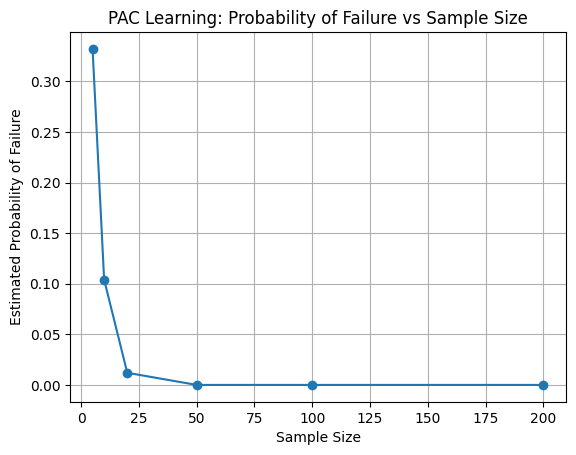

In [27]:
#Visualize the probability of failure
plt.plot(sample_sizes, pac_probabilities, marker='o')
plt.xlabel('Sample Size')
plt.ylabel('Estimated Probability of Failure')
plt.title('PAC Learning: Probability of Failure vs Sample Size')
plt.grid(True)
plt.show()

The estimated probability \(P(L(h) > $\epsilon$\) decreases as the training sample size increases. This indicates that with the realizability assumption, larger training samples make it less likely that the learned hypothesis has a true error greater than the tolerated error \($\epsilon$=0.1\). This experimentally illustrates the expected behavior of PAC learning.

## 5. From PAC to Agnostic PAC

We repeat the learning experiment after introducing label noise

In [ ]:
#There is a 10% probability that any given training label is wrong
eta = 0.1

In [29]:
#Generate a dataset with noise
def generate_noisy_dataset(m, theta, eta):

    X = np.random.uniform(0, 1, m)
    Y = np.where(X > theta, 1, 0)

    # Generate noise
    noise = np.random.random(m) < eta

    #Flip the labels of the noisy samples
    Y[noise] = 1 - Y[noise]
    
    return X, Y

In [30]:
#Test the noisy dataset generation

X_noisy, Y_noisy = generate_noisy_dataset(20, theta, eta)

print("X:", X_noisy)
print("Y:", Y_noisy)

X: [0.53002115 0.61552749 0.70948577 0.54473327 0.32843121 0.6277292
 0.13909473 0.21684982 0.2482461  0.08488486 0.50357231 0.30204162
 0.87611643 0.74867151 0.00645467 0.24719887 0.51938615 0.63510758
 0.34795068 0.94454551]
Y: [0 1 1 0 0 1 0 0 0 0 0 0 1 1 0 1 0 1 0 1]


In [38]:
#The ERM algorithm for the noisy case: 
#Try possible thresholds and choose the one that produces the smallest empirical error.
def ERM_Noise(X, Y):

    # Sort the data according to X
    sorted_indices = np.argsort(X)
    X_sorted = X[sorted_indices]
    Y_sorted = Y[sorted_indices]

    # Start with a threshold at 0
    best_theta = 0
    best_error = len(Y)

    # Try thresholds between consecutive X values
    for i in range(len(X_sorted) - 1):

        theta_candidate = (X_sorted[i] + X_sorted[i + 1]) / 2

        # Predict labels using this threshold
        Y_pred = np.where(X > theta_candidate, 1, 0)

        # Calculate the number of mistakes
        error = np.sum(Y_pred != Y)

        # Keep the threshold with the smallest error
        if error < best_error:
            best_error = error
            best_theta = theta_candidate

    return best_theta

In [33]:
#Test the ERM algorithm on the noisy dataset
theta_hat_noisy = ERM_Noise(X_noisy, Y_noisy)

print("True theta:", theta)
print("Estimated theta:", theta_hat_noisy)

True theta: 0.6
Estimated theta: 0.5801303780282394


In [35]:
#Make predictions on the noisy dataset and compute empirical error
Y_noisy_pred = np.where(X_noisy > theta_hat_noisy, 1, 0)
empirical_error_noisy = np.mean(Y_noisy_pred != Y_noisy)

print("Empirical error:", empirical_error_noisy)

#Empirical error is not 0 anymore due to the noise in the labels

Empirical error: 0.05


In the realizable setting, the empirical error can reach zero because the training labels are perfectly consistent with the target threshold. In the agnostic setting, label noise can make the training data inconsistent with any threshold, so the empirical error may no longer be zero. ERM therefore selects the threshold that minimizes the empirical error.

In [36]:
#Generate a large test dataset to evaluate the performance of the ERM algorithm on the noisy dataset
X_test, Y_test = generate_dataset(10000, theta)

Y_test_pred = np.where(X_test > theta_hat_noisy, 1, 0)
true_error_noisy = np.mean(Y_test_pred != Y_test)

print("True error:", true_error_noisy)

True error: 0.0181


In [ ]:
#Generate noisy datasets of different sizes and evaluate the performance of the ERM algorithm on them
agnostic_probabilities = []

for m in sample_sizes:

    failure_count = 0

    for i in range(n_repetitions):

        # Generate a new noisy training dataset
        X_noisy, Y_noisy = generate_noisy_dataset(m, theta, eta)

        # Learn the threshold using ERM
        theta_hat_noisy = ERM_Noise(X_noisy, Y_noisy)

        # Generate an independent clean test dataset
        X_test, Y_test = generate_dataset(10000, theta)

        # Make predictions
        Y_test_pred = np.where(X_test > theta_hat_noisy, 1, 0)

        # Calculate the true error
        true_error = np.mean(Y_test_pred != Y_test)

        # Check if the true error is greater than epsilon
        failure = true_error > epsilon

        if failure:
            failure_count += 1

    # Estimate the probability of failure
    probability = failure_count / n_repetitions
    agnostic_probabilities.append(probability)

    print("Sample size:", m)
    print("Number of failures:", failure_count)
    print("Estimated probability:", probability)
    print()

#I noticed that as the sample size increases, the estimated probability of failure decreases
#The probabilities of failure are generally higher than in the noise-free case
#especially for smaller sample sizes

#This shows that learning is more difficult when the training data contains noise
#which is consistent with the agnostic PAC learning setting

Sample size: 5
Number of failures: 209
Estimated probability: 0.418

Sample size: 10
Number of failures: 127
Estimated probability: 0.254

Sample size: 20
Number of failures: 63
Estimated probability: 0.126

Sample size: 50
Number of failures: 10
Estimated probability: 0.02

Sample size: 100
Number of failures: 1
Estimated probability: 0.002

Sample size: 200
Number of failures: 0
Estimated probability: 0.0



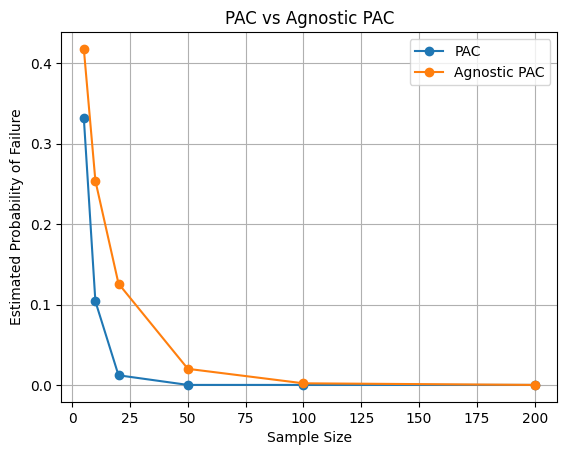

In [45]:
#Visualize the probabilities of failure for both PAC and Agnostic PAC learning

plt.plot(sample_sizes, pac_probabilities, marker='o', label='PAC')
plt.plot(sample_sizes, agnostic_probabilities, marker='o', label='Agnostic PAC')

plt.xlabel('Sample Size')
plt.ylabel('Estimated Probability of Failure')
plt.title('PAC vs Agnostic PAC')
plt.legend()
plt.grid(True)
plt.show()

The probability of failure is higher in the Agnostic PAC setting because the training data contains noisy labels. The learner therefore has more difficulty finding a hypothesis with low true error. However, in both settings, the probability of failure decreases as the training sample size increases.

## Conclusion

The experiments show that the probability of failure decreases as the training sample size increases in both the PAC and Agnostic PAC settings.

In the realizable PAC setting, the training labels are noise-free, so ERM can achieve an empirical error of zero. The probability of having a true error greater than $\epsilon$ decreases quickly as the sample size increases.

In the Agnostic PAC setting, the training labels contain noise. As a result, the empirical error is not necessarily zero, and the probability of failure is generally higher than in the noise-free setting, especially for smaller sample sizes.

Overall, the experiments show that label noise makes learning more difficult, but increasing the amount of training data still improves generalization.